# Interpolação polinomial: compreender, explorar e comparar

**Cálculo Numérico | Atividade guiada no Google Colab**

**Aluno:** Felipe Pinto Zanata — UNIFESP · Profa. Raquel Lobosco

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Z4nata/CalculoNumerico/blob/main/Atividade_7.ipynb)  


## Objetivos

Ao final, vocês deverão conseguir:

- distinguir interpolação de extrapolação;
- construir e avaliar um polinômio que passa por pontos dados;
- comparar formas de representação e reconhecer limitações numéricas;
- investigar como a escolha dos nós afeta o resultado.

> **Como usar:** leiam cada seção, executem as células de código e preencham os campos de resposta. As células com `# SUA RESPOSTA` podem ser editadas pelo grupo.

> **Versão respondida pelo grupo.** As respostas estão nos campos **Resposta do grupo** (no lugar de `# SUA RESPOSTA`) e logo abaixo de cada pergunta. As células marcadas como **Complemento do grupo** são extras: conferem à mão o que o NumPy calculou, testam as previsões feitas antes dos experimentos e explicam o código.
>
> Para rodar no Colab: *Ambiente de execução → Executar tudo*.

## 1. Ideia central: preencher valores entre medições

Suponha que uma tabela contenha medições $(x_i,y_i)$. Um polinômio interpolador $P(x)$ é escolhido para reproduzir exatamente os dados nos nós:

$$P(x_i)=y_i,\qquad i=0,1,\ldots,n.$$

Assim, se conhecemos medições em alguns instantes, podemos estimar a medida em um instante intermediário. A interpolação **não recupera automaticamente a realidade**: ela constrói uma curva compatível com os dados e com o método escolhido.

- **Interpolar:** estimar dentro do intervalo coberto pelos nós.
- **Extrapolar:** estimar fora desse intervalo; em geral, exige mais cautela.

**Antes de executar:** pensem numa situação em que seria útil estimar um valor entre duas medições. O que poderia tornar essa estimativa pouco confiável?

**Resposta do grupo:** Um exemplo é uma estação meteorológica que registra a temperatura de hora em hora. Se às 14h marcou 26 °C e às 15h marcou 28 °C, interpolar permite estimar a temperatura às 14h30 sem ter medido. O mesmo acontece ao consultar uma tabela (de vapor, de juros, de densidade) quando o valor procurado fica entre duas linhas.

A estimativa fica pouco confiável quando:
- as medições têm erro ou ruído, porque a curva é obrigada a passar exatamente por elas;
- os pontos estão muito espaçados e o fenômeno pode mudar bastante entre eles (uma chuva às 14h20 derrubaria a temperatura, e nenhuma curva "veria" isso);
- o fenômeno tem saltos ou mudanças bruscas, que um polinômio suave não representa;
- usamos muitos pontos com um polinômio de grau alto, que pode oscilar entre eles;
- o valor procurado está fora do intervalo medido, e aí já é extrapolação.

## 2. Dados, nós e grau

Os valores $x_i$ são chamados **nós**. Os pares $(x_i,y_i)$ são os dados que a curva deve reproduzir. Com $m$ nós distintos, existe um único polinômio de grau no máximo $m-1$ que passa por todos eles.

Por exemplo, quatro pontos determinam um polinômio de grau no máximo 3. O grau pode ser menor se os dados já pertencerem a um polinômio mais simples.

### Atenção à palavra “exatamente”
O polinômio construído passa pelos pontos informados (salvo pequenos erros de arredondamento computacional). Isso não garante que ele represente bem o comportamento entre pontos, nem que seja um bom modelo fora do intervalo.

**Previsão:** se acrescentarmos um ponto novo, o polinômio precisa continuar passando pelos pontos antigos? O formato da curva pode mudar?

**Resposta antes do teste:** Sim, precisa. A condição $P(x_i)=y_i$ continua valendo para **todos** os nós, inclusive os antigos, então o novo polinômio passa pelos pontos antigos e pelo novo. Mas o formato da curva pode mudar, e em geral muda: com um nó a mais, o grau máximo sobe de $m-1$ para $m$, e a curva entre os nós e fora do intervalo fica diferente. Só não muda nada se o ponto novo já estiver sobre o polinômio anterior.

*(Testamos essa previsão no complemento da seção 5.)*

## 3. Primeiro exemplo: observar antes de formalizar

Vamos usar quatro pontos. Observem os dados e descrevam o padrão que imaginam antes de ver a curva.

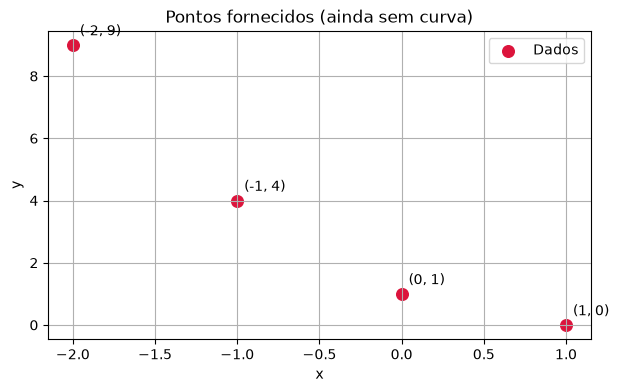

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([-2, -1, 0, 1], dtype=float)
y = np.array([9, 4, 1, 0], dtype=float)

plt.figure(figsize=(7, 4))
plt.scatter(x, y, color="crimson", s=70, label="Dados")
for xi, yi in zip(x, y):
    plt.annotate(f"({xi:g}, {yi:g})", (xi, yi), xytext=(5, 7), textcoords="offset points")
plt.xlabel("x"); plt.ylabel("y"); plt.title("Pontos fornecidos (ainda sem curva)")
plt.grid(True); plt.legend(); plt.show()

**Descrevam a tendência dos pontos.** A curva precisa ser reta? Há mais de uma curva que poderia passar pelos pontos?

**Resposta do grupo:** Os valores de $y$ diminuem (9, 4, 1, 0), mas cada vez mais devagar: as diferenças entre pontos vizinhos são $-5$, $-3$ e $-1$, e as diferenças dessas diferenças são constantes ($+2$). Diferenças segundas constantes são a marca de uma **parábola**. Além disso, 9, 4, 1, 0 são $3^2, 2^2, 1^2, 0^2$, o que sugere $y=(x-1)^2$.

A curva **não** precisa ser reta, e nem pode: as inclinações entre pontos vizinhos ($-5$, $-3$, $-1$) são diferentes, então os pontos não estão alinhados. E há **infinitas** curvas que passam pelos quatro pontos. Por exemplo, $(x-1)^2 + k\,(x+2)(x+1)\,x\,(x-1)$ serve para qualquer $k$, porque o termo extra vale zero nos quatro nós. O que é único é o polinômio de grau **no máximo 3**.

## 4. Construindo o polinômio com uma ferramenta

Usaremos `numpy.polynomial.Polynomial.fit` para obter o polinômio de grau até $m-1$. O método faz o cálculo numericamente e depois convertemos para a forma usual em potências de $x$.

A expressão impressa pode conter coeficientes muito pequenos, como $10^{-14}$, que representam zero dentro da precisão numérica. Não confundam esses resíduos de arredondamento com termos relevantes.

In [2]:
polinomio = np.polynomial.Polynomial.fit(x, y, deg=len(x)-1).convert()
print("Polinômio na forma usual:")
print(polinomio)
print("\nCoeficientes em ordem crescente (termo constante primeiro):")
print(polinomio.coef)

Polinômio na forma usual:
1.0 - 2.0 x + 1.0 x**2 + (1.1157452e-15) x**3

Coeficientes em ordem crescente (termo constante primeiro):
[ 1.0000000e+00 -2.0000000e+00  1.0000000e+00  1.1157452e-15]


**Entendendo o código.** `Polynomial.fit(x, y, deg)` é, na verdade, uma função de **ajuste por mínimos quadrados** (regressão). Quando pedimos `deg = len(x) - 1`, o polinômio tem tantos coeficientes quanto pontos, o ajuste consegue erro zero e vira interpolação. Por dentro, o `fit` trabalha com uma variável reescalada para o intervalo $[-1,1]$, que é mais estável numericamente. O `.convert()` volta para a variável $x$ original, e é nessa conta que aparecem os resíduos de arredondamento. `polinomio.coef` traz os coeficientes do termo constante para o de maior grau, e `polinomio(x)` avalia o polinômio num número ou num vetor inteiro de uma vez.

### Interpretando a expressão

Na forma usual, um polinômio cúbico é escrito como $P(x)=a_0+a_1x+a_2x^2+a_3x^3$. O vetor de coeficientes retornado pelo NumPy segue essa ordem: constante, $x$, $x^2$, $x^3$.

**Registrem a expressão obtida e identifiquem seu grau.** Se algum coeficiente for praticamente zero, indiquem isso.

**Resposta do grupo:** O NumPy devolveu

$$P(x) = 1 - 2x + 1\,x^2 + (\text{algo da ordem de }10^{-15})\,x^3,$$

ou seja, $P(x)=x^2-2x+1=(x-1)^2$. O coeficiente de $x^3$ é praticamente zero: é resíduo de arredondamento, e o valor exato muda de um computador para outro. Logo o polinômio interpolador tem **grau 2**, mesmo podendo ter grau até 3, porque os quatro pontos já estão sobre uma parábola, como previmos na seção 3.

In [3]:
# Conferência automática: comparar P(x_i) com cada y_i
valores_nos_nos = polinomio(x)
for xi, yi, pi in zip(x, y, valores_nos_nos):
    print(f"x={xi:5.1f} | dado={yi:10.6f} | P(x)={pi:10.6f} | diferença={abs(yi-pi):.2e}")

x= -2.0 | dado=  9.000000 | P(x)=  9.000000 | diferença=3.55e-15
x= -1.0 | dado=  4.000000 | P(x)=  4.000000 | diferença=1.33e-15
x=  0.0 | dado=  1.000000 | P(x)=  1.000000 | diferença=2.22e-15
x=  1.0 | dado=  0.000000 | P(x)=  0.000000 | diferença=8.88e-16


**Perguntas de interpretação**

1. As diferenças são zero ou muito pequenas?
2. O que essa conferência mostra sobre a curva nos nós?
3. O que ela **não** mostra sobre valores entre os nós ou fora do intervalo?

**Respostas:**

1. São muito pequenas, da ordem de $10^{-15}$ a $10^{-16}$, mas não exatamente zero. O computador guarda números com cerca de 16 algarismos significativos (precisão dupla, $\varepsilon \approx 2{,}2\times10^{-16}$), então diferenças desse tamanho são arredondamento, não erro do método.
2. Mostra que o polinômio calculado cumpre a condição de interpolação $P(x_i)=y_i$ nos quatro nós: a curva passa pelos pontos dados.
3. Não mostra nada sobre os outros valores de $x$. Infinitas funções passam pelos mesmos quatro pontos e passariam nessa conferência do mesmo jeito. Para saber se $P$ representa bem o fenômeno **entre** os nós, precisaríamos de medições extras (pontos de teste) ou de conhecer o fenômeno. Fora do intervalo $[-2,1]$ a conferência diz menos ainda, porque ali nenhum dado limita a curva.

### Complemento do grupo: conferindo à mão com diferenças divididas

Para entender **por que** o termo de $x^3$ deu (quase) zero, montamos a tabela de diferenças divididas, que leva à forma de Newton. Cada coluna é

$$f[x_i,\dots,x_{i+k}] = \frac{f[x_{i+1},\dots,x_{i+k}] - f[x_i,\dots,x_{i+k-1}]}{x_{i+k}-x_i}.$$

| $x_i$ | $y_i$ | 1ª ordem | 2ª ordem | 3ª ordem |
|---|---|---|---|---|
| $-2$ | $9$ | $\frac{4-9}{-1-(-2)}=-5$ | $\frac{-3-(-5)}{0-(-2)}=1$ | $\frac{1-1}{1-(-2)}=0$ |
| $-1$ | $4$ | $\frac{1-4}{0-(-1)}=-3$ | $\frac{-1-(-3)}{1-(-1)}=1$ | |
| $0$ | $1$ | $\frac{0-1}{1-0}=-1$ | | |
| $1$ | $0$ | | | |

A primeira linha dá os coeficientes da forma de Newton:

$$P(x) = 9 - 5(x+2) + 1\,(x+2)(x+1) + 0\,(x+2)(x+1)\,x .$$

A diferença de 3ª ordem é **exatamente 0**, e por isso o grau é 2. Expandindo: $9 - 5x - 10 + x^2 + 3x + 2 = x^2 - 2x + 1$. ✔

A célula abaixo faz a mesma conta em Python. Detalhe de código: o laço interno anda **de trás para frente**, para não sobrescrever um valor que ainda vai ser usado na mesma coluna.

In [4]:
def diferencas_divididas(x_nos, y_nos):
    """Devolve os coeficientes da forma de Newton: f[x0], f[x0,x1], f[x0,x1,x2], ..."""
    coef = np.array(y_nos, dtype=float)   # cópia: não altera o vetor original
    n = len(x_nos)
    for ordem in range(1, n):
        for i in range(n - 1, ordem - 1, -1):   # de trás para frente
            coef[i] = (coef[i] - coef[i - 1]) / (x_nos[i] - x_nos[i - ordem])
    return coef

def avalia_newton(coef, x_nos, t):
    """Avalia a forma de Newton de dentro para fora (esquema de Horner)."""
    resultado = coef[-1]
    for k in range(len(coef) - 2, -1, -1):
        resultado = resultado * (t - x_nos[k]) + coef[k]
    return resultado

coef_newton = diferencas_divididas(x, y)
print("Coeficientes da forma de Newton:", coef_newton)
for t in [-1.5, 0.5]:
    print(f"P({t:4.1f}) pela forma de Newton = {avalia_newton(coef_newton, x, t)}")

Coeficientes da forma de Newton: [ 9. -5.  1.  0.]
P(-1.5) pela forma de Newton = 6.25
P( 0.5) pela forma de Newton = 0.25


Na forma de Newton as contas saem **exatas** ($9, -5, 1, 0$ e $P(-1{,}5)=6{,}25$, sem resíduo), porque só envolvem somas e divisões de números pequenos que o computador representa sem erro.

#### Quatro formas, um só polinômio

O polinômio interpolador é **único**, mas pode ser escrito de vários jeitos, e cada ferramenta escolhe o seu:

| Forma | Expressão | Onde aparece |
|---|---|---|
| Potências (usual) | $1 - 2x + x^2$ | NumPy (`.convert()`), GeoGebra |
| Newton | $9 - 5(x+2) + (x+2)(x+1)$, que é o mesmo que $(x-4)(x+2)+9$ | diferenças divididas; resultado principal do WolframAlpha |
| Lagrange | $\displaystyle\sum_{i=0}^{3} y_i\,L_i(x)$, com $L_i(x)=\prod_{j\ne i}\frac{x-x_j}{x_i-x_j}$ | fórmula teórica |
| Fatorada | $(x-1)^2$ | forma alternativa do WolframAlpha |

A forma de Newton tem uma vantagem prática: acrescentar um ponto só acrescenta um termo, sem refazer os anteriores. A de Lagrange mostra quanto cada dado $y_i$ pesa na curva, e vamos usar isso na seção 8.

## 5. Visualizar não é o mesmo que validar

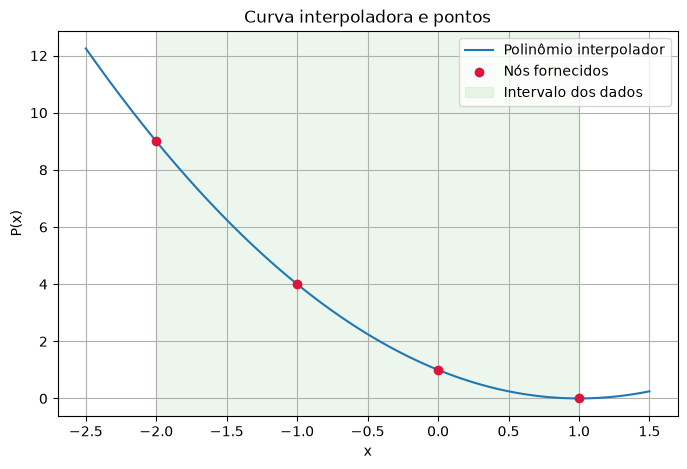

In [5]:
xx = np.linspace(x.min()-0.5, x.max()+0.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx, polinomio(xx), label="Polinômio interpolador")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós fornecidos")
plt.axvspan(x.min(), x.max(), color="green", alpha=0.07, label="Intervalo dos dados")
plt.xlabel("x"); plt.ylabel("P(x)"); plt.title("Curva interpoladora e pontos")
plt.grid(True); plt.legend(); plt.show()

O gráfico ajuda a perceber a forma da curva, mas uma figura pode esconder diferenças pequenas ou induzir a confiar demais em uma região sem dados. A faixa sombreada é o intervalo de interpolação; fora dela estamos extrapolando.

**Descrevam:** a curva passa pelos pontos? O comportamento fora do intervalo parece sustentado pelos dados?

**Resposta do grupo:** Sim, a curva passa pelos quatro nós (o que já tinha sido conferido numericamente na seção 4). Dentro da faixa verde, $[-2,1]$, o comportamento é coerente com os dados: a curva desce e vai achatando até $y=0$ em $x=1$.

Fora dela, não. Para $x>1$ a parábola volta a subir (por exemplo, $P(1{,}5)=0{,}25$) e para $x<-2$ cresce rápido ($P(-2{,}5)=12{,}25$). Isso vem da forma do polinômio, não de alguma medição: nenhum dado mostra que $y$ volta a subir depois de $x=1$, e o fenômeno poderia, por exemplo, ficar parado em zero. Como o mínimo da parábola cai justamente no último nó, toda a "subida" à direita é extrapolação.

### Complemento do grupo: testando a previsão da seção 2

Acrescentamos o ponto $(2,\,3)$. Se os dados seguissem a parábola $(x-1)^2$, o valor em $x=2$ seria $1$. Usamos $3$ de propósito, para o ponto **não** estar sobre a curva antiga. Agora são 5 nós, então o novo polinômio pode ter grau até 4.

Novo polinômio: 1.0 - 2.16666667 x + 0.91666667 x**2 + 0.16666667 x**3 + 0.08333333 x**4
Maior diferença nos 4 nós antigos: 3.6e-15
Diferença no nó novo (2, 3): 3.6e-15
x = -1.5: antes P = 6.250000 | depois P = 6.171875
x =  0.5: antes P = 0.250000 | depois P = 0.171875


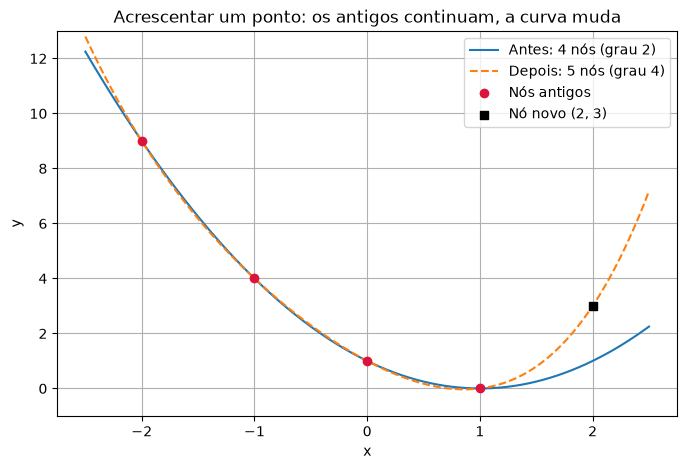

In [6]:
x_novo = np.append(x, 2.0)   # np.append devolve um vetor NOVO; x continua igual
y_novo = np.append(y, 3.0)
p_novo = np.polynomial.Polynomial.fit(x_novo, y_novo, deg=len(x_novo)-1).convert()

print("Novo polinômio:", p_novo)
print(f"Maior diferença nos 4 nós antigos: {np.max(np.abs(p_novo(x) - y)):.1e}")
print(f"Diferença no nó novo (2, 3): {abs(p_novo(2.0) - 3.0):.1e}")
for q in [-1.5, 0.5]:
    print(f"x = {q:4.1f}: antes P = {polinomio(q):.6f} | depois P = {p_novo(q):.6f}")

xx2 = np.linspace(-2.5, 2.5, 400)
plt.figure(figsize=(8, 5))
plt.plot(xx2, polinomio(xx2), label="Antes: 4 nós (grau 2)")
plt.plot(xx2, p_novo(xx2), "--", label="Depois: 5 nós (grau 4)")
plt.scatter(x, y, color="crimson", zorder=3, label="Nós antigos")
plt.scatter([2], [3], color="black", marker="s", zorder=4, label="Nó novo (2, 3)")
plt.ylim(-1, 13); plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y")
plt.title("Acrescentar um ponto: os antigos continuam, a curva muda"); plt.show()

**Resultado do teste:** a previsão se confirmou. Os quatro pontos antigos continuam sendo reproduzidos (diferença da ordem de $10^{-15}$) e o ponto novo também, mas a curva mudou: o grau subiu de 2 para 4, $P(-1{,}5)$ passou de $6{,}25$ para $\approx 6{,}17$ e $P(0{,}5)$ de $0{,}25$ para $\approx 0{,}17$. Mudou até em regiões longe do ponto novo.

Na forma de Newton isso é imediato: $P_{\text{novo}}(x) = P(x) + c\,(x+2)(x+1)\,x\,(x-1)$, e o termo novo vale zero nos quatro nós antigos. Aqui $c=\frac{3-1}{4\cdot3\cdot2\cdot1}=\frac{1}{12}$.

## 6. Calcular valores intermediários

Escolham valores que não aparecem na tabela. O resultado de $P(x)$ é uma estimativa interpolada quando $x$ está entre o menor e o maior nó.

In [7]:
consultas = np.array([-1.5, -0.5, 0.5, 0.9, 2.0])
for q in consultas:
    tipo = "interpolação" if x.min() <= q <= x.max() else "extrapolação"
    print(f"P({q:4.1f}) = {polinomio(q): .6f}  ({tipo})")

P(-1.5) =  6.250000  (interpolação)
P(-0.5) =  2.250000  (interpolação)
P( 0.5) =  0.250000  (interpolação)
P( 0.9) =  0.010000  (interpolação)
P( 2.0) =  1.000000  (extrapolação)


**Tabela de registro**

| $x$ consultado | Estimativa $P(x)$ | Interpolação ou extrapolação? |
|---|---|---|
| $-1{,}5$ | $6{,}25$ | Interpolação (entre os nós $-2$ e $-1$) |
| $-0{,}5$ | $2{,}25$ | Interpolação (entre $-1$ e $0$) |
| $0{,}5$ | $0{,}25$ | Interpolação (entre $0$ e $1$) |
| $0{,}9$ | $0{,}01$ | Interpolação (entre $0$ e $1$, perto do nó $1$) |
| $2{,}0$ | $1{,}00$ | **Extrapolação** ($2$ é maior que o último nó, $1$) |

Como $P(x)=(x-1)^2$, dá para conferir de cabeça: $(-2{,}5)^2=6{,}25$, $(-1{,}5)^2=2{,}25$, $(-0{,}5)^2=0{,}25$, $(-0{,}1)^2=0{,}01$ e $1^2=1$. O único valor que merece desconfiança é o de $x=2$: ele depende de a parábola continuar valendo depois do último dado, e nada garante isso.

*Detalhe do código:* `x.min() <= q <= x.max()` é uma comparação encadeada do Python, equivalente a `x.min() <= q and q <= x.max()`.

### Atividade: comparar ferramentas

Pesquisem pelo menos **duas** ferramentas além deste código (por exemplo GeoGebra, WolframAlpha, SageMath ou calculadora online). Insiram os mesmos pontos e comparem a expressão e os valores em $x=-1{,}5$ e $x=0{,}5$.

| Ferramenta e link | Como inseriram os dados? | Expressão/resultado | O que foi fácil ou difícil? |
|---|---|---|---|
| 1. **WolframAlpha**: [wolframalpha.com](https://www.wolframalpha.com) | Comando `InterpolatingPolynomial[{{-2,9},{-1,4},{0,1},{1,0}}, x]`. Para os valores: o mesmo comando seguido de `/. x -> {-1.5, 0.5}` | Resultado: $(x-4)(x+2)+9$ (forma de Newton). "Expanded form": $x^2-2x+1$. Forma alternativa: $(x-1)^2$. Valores: $\{6{,}25;\ 0{,}25\}$ | Fácil: um comando só, e ele mostra várias formas equivalentes. Difícil: exige a sintaxe do Wolfram (listas com chaves), e a primeira expressão não vem na forma usual, então parece diferente até expandir. Ele tratou a substituição como "limite", mas o valor saiu certo. |
| 2. **GeoGebra** (Calculadora Gráfica): [geogebra.org/calculator](https://www.geogebra.org/calculator) | Na Entrada: `P(x)=Polynomial({(-2,9),(-1,4),(0,1),(1,0)})` (na interface em português o comando aparece como `Polinômio`). Depois, `P(-1.5)` e `P(0.5)` | $P(x)=x^2-2x+1$, $P(-1{,}5)=6{,}25$ e $P(0{,}5)=0{,}25$, com o gráfico da parábola (vértice em $(1,0)$) | Fácil: o gráfico aparece na hora e dá para avaliar $P$ em qualquer ponto. Difícil: achar o comando certo, porque existe também o `FitPoly`, que é **regressão** e só coincide com a interpolação quando o grau é número de pontos − 1. O separador decimal é ponto, não vírgula. |

Se os resultados diferirem, verifiquem se a ferramenta calculou interpolação polinomial, regressão, spline ou arredondou coeficientes. São operações diferentes.

#### Prints das ferramentas

**WolframAlpha** (em cima, os valores em $x=-1{,}5$ e $x=0{,}5$; embaixo, o polinômio e suas formas):

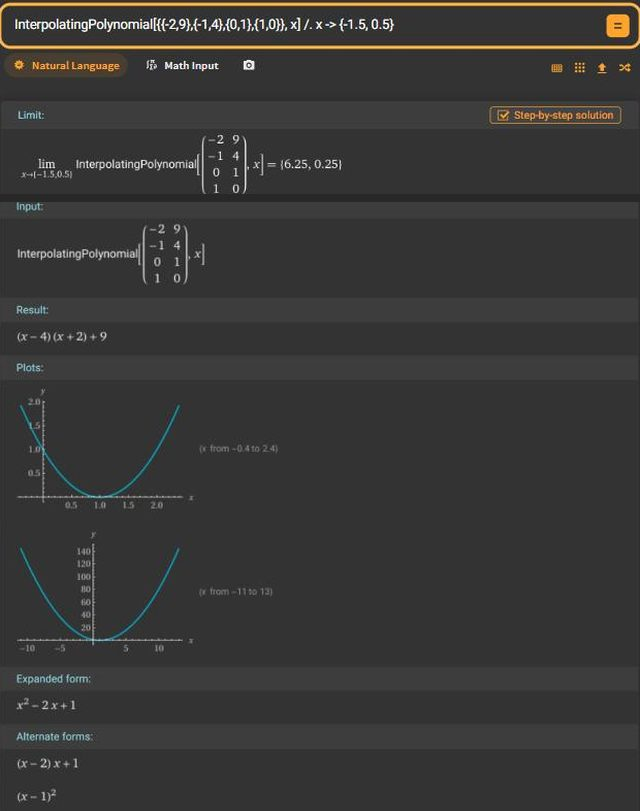

**GeoGebra** (o polinômio, $a=P(-1{,}5)$ e $b=P(0{,}5)$):

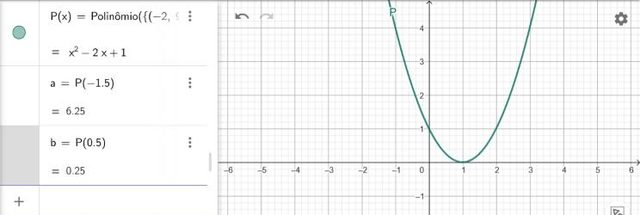

**As ferramentas concordaram?** Sim. NumPy, WolframAlpha e GeoGebra chegaram ao mesmo polinômio, $x^2-2x+1$, e aos mesmos valores, $P(-1{,}5)=6{,}25$ e $P(0{,}5)=0{,}25$, como tinha de ser, já que o polinômio interpolador é único. As diferenças foram só de apresentação:
- o WolframAlpha devolveu primeiro a forma de Newton e calcula com aritmética exata, por isso não aparece o resíduo de $x^3$;
- o GeoGebra mostra o resultado arredondado (2 casas decimais, por padrão), então um resíduo de $10^{-15}$ nem apareceria;
- o NumPy calcula em ponto flutuante e mostra o resíduo.

Nenhuma das duas ferramentas fez regressão nem spline.

## 7. Segundo conjunto: dados de medição

Agora considere uma sequência simplificada de medições. O valor de $x$ pode representar tempo, e $y$ uma grandeza observada.

1.2 + 1.11666667 x - 0.45 x**2 + 0.13333333 x**3
Estimativa em x=1.5: 2.312500


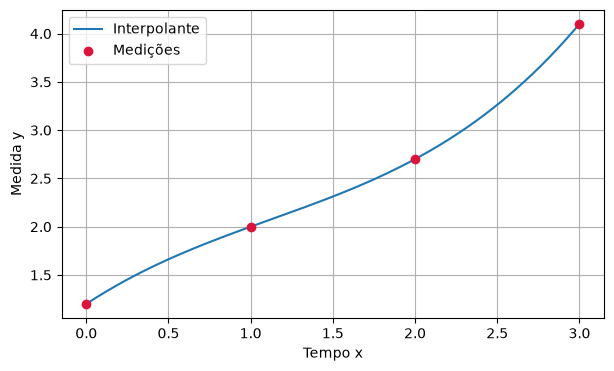

In [8]:
xB = np.array([0, 1, 2, 3], dtype=float)
yB = np.array([1.2, 2.0, 2.7, 4.1], dtype=float)
pB = np.polynomial.Polynomial.fit(xB, yB, deg=len(xB)-1).convert()
print(pB)
print(f"Estimativa em x=1.5: {pB(1.5):.6f}")
xb_plot = np.linspace(xB.min(), xB.max(), 300)
plt.figure(figsize=(7,4)); plt.plot(xb_plot,pB(xb_plot),label="Interpolante")
plt.scatter(xB,yB,color="crimson",label="Medições",zorder=3)
plt.xlabel("Tempo x"); plt.ylabel("Medida y"); plt.grid(True); plt.legend(); plt.show()

**Discussão:** $x=1{,}5$ está entre nós? Qual a estimativa?


**Resposta do grupo:** Sim. $x=1{,}5$ fica entre os nós $1$ e $2$, dentro do intervalo $[0,3]$ das medições, então é **interpolação**. A estimativa é $P_B(1{,}5)=2{,}3125\approx2{,}31$, com

$$P_B(x)=1{,}2+1{,}11667\,x-0{,}45\,x^2+0{,}13333\,x^3 \quad\left(=1{,}2+\tfrac{67}{60}x-\tfrac{9}{20}x^2+\tfrac{2}{15}x^3\right).$$

Para comparar: a interpolação **linear** entre os dois vizinhos daria a média $(2{,}0+2{,}7)/2=2{,}35$. A cúbica dá um pouco menos porque leva em conta os quatro pontos. O salto grande entre $x=2$ e $x=3$ (de $2{,}7$ para $4{,}1$) faz a curva já estar "acelerando" (côncava para cima) entre $1$ e $2$, e uma curva côncava para cima fica abaixo da reta que liga os dois vizinhos.

## 8. Experimento: alterar uma medição

Ajustem somente o valor medido em $x=2$ e observem o efeito na curva. Abaixo usamos uma alteração de $+0{,}5$; vocês podem testar outra.

Estimativa original em x=1.5: 2.312499999999999
Estimativa alterada em x=1.5: 2.5937499999999996


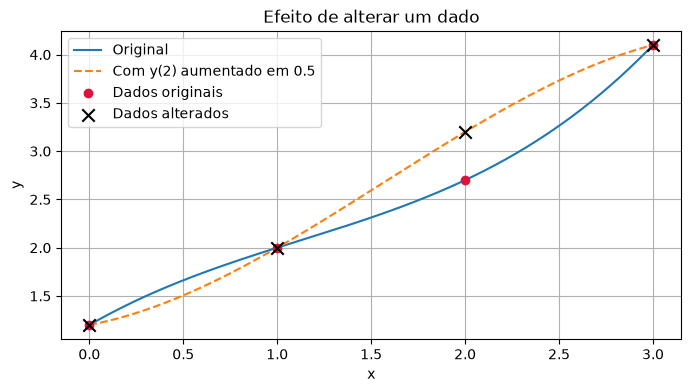

In [9]:
yB_alterado = yB.copy()
yB_alterado[2] += 0.5
pB_alterado = np.polynomial.Polynomial.fit(xB, yB_alterado, deg=len(xB)-1).convert()
print("Estimativa original em x=1.5:", pB(1.5))
print("Estimativa alterada em x=1.5:", pB_alterado(1.5))
plt.figure(figsize=(8,4))
plt.plot(xb_plot,pB(xb_plot),label="Original")
plt.plot(xb_plot,pB_alterado(xb_plot),"--",label="Com y(2) aumentado em 0.5")
plt.scatter(xB,yB,color="crimson",zorder=3,label="Dados originais")
plt.scatter(xB,yB_alterado,marker="x",s=80,color="black",zorder=4,label="Dados alterados")
plt.grid(True); plt.legend(); plt.xlabel("x"); plt.ylabel("y"); plt.title("Efeito de alterar um dado"); plt.show()

**Registrem:** qual ponto foi alterado? O que aconteceu ao valor em $x=1{,}5$? A curva mudou apenas perto do ponto alterado? Por que pequenas incertezas de medição podem ser importantes?

**Resposta do grupo:**
- **Ponto alterado:** a medição em $x=2$, de $2{,}7$ para $3{,}2$ ($+0{,}5$). Os outros três dados ficaram iguais.
- **Efeito em $x=1{,}5$:** a estimativa passou de $2{,}3125$ para $2{,}59375$, um aumento de $0{,}28125$, mais da metade da alteração feita no dado.
- **A curva mudou só perto do ponto?** Não. Ela continua passando pelos nós $0$, $1$ e $3$ (é obrigada a isso), mas mudou em todo o resto: entre $2$ e $3$ subiu (em $x=2{,}5$, $+0{,}47$) e entre $0$ e $1$ chegou a **descer** (em $x=0{,}5$, $-0{,}16$). Todos os coeficientes mudaram, e o de $x^3$ até trocou de sinal ($0{,}133 \to -0{,}117$).
- **Por que pequenas incertezas importam:** a interpolação reproduz cada dado exatamente, inclusive o erro dele. Uma incerteza de $\pm0{,}5$ num único sensor muda a curva inteira, e o efeito é maior longe dos dados: em $x=4$ (extrapolação) a mesma alteração mudaria a estimativa em $3$ unidades, seis vezes a alteração original (veja o complemento abaixo).

### Complemento do grupo: por que a curva inteira mudou?

Na forma de Lagrange, $P(x)=\sum_i y_i\,L_i(x)$. Mudar só $y_2$ (o dado em $x=2$) em $\Delta=0{,}5$ muda o polinômio em

$$P_{\text{alterado}}(x)-P(x) = \Delta\cdot L_2(x), \qquad L_2(x)=\frac{(x-0)(x-1)(x-3)}{(2-0)(2-1)(2-3)} = -\frac{x(x-1)(x-3)}{2}.$$

$L_2$ vale $1$ em $x=2$ e $0$ nos outros nós, mas **não é zero no resto**: é um polinômio cúbico que se espalha por todo o eixo. A célula abaixo confere que a diferença entre as duas curvas é exatamente $0{,}5\,L_2(x)$.

In [10]:
def L2(t):
    # polinômio de Lagrange do nó x = 2 (nós: 0, 1, 2, 3)
    return (t - 0) * (t - 1) * (t - 3) / ((2 - 0) * (2 - 1) * (2 - 3))

def limpa(v, casas=5):
    # arredonda; o "+ 0.0" transforma -0.0 em 0.0 (o Python distingue os dois ao imprimir)
    return np.round(v, casas) + 0.0

print("  x  | P_alterado(x) − P(x) | 0,5·L2(x)")
for t in [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
    print(f"{t:4.1f} | {limpa(pB_alterado(t) - pB(t)):20.5f} | {limpa(0.5 * L2(t)):9.5f}")

  x  | P_alterado(x) − P(x) | 0,5·L2(x)
 0.5 |             -0.15625 |  -0.15625
 1.0 |              0.00000 |   0.00000
 1.5 |              0.28125 |   0.28125
 2.0 |              0.50000 |   0.50000
 2.5 |              0.46875 |   0.46875
 3.0 |              0.00000 |   0.00000
 4.0 |             -3.00000 |  -3.00000


## 9. Quando o grau alto pode ser um problema?

Com muitos pontos, o polinômio interpolador pode oscilar entre nós, especialmente quando os pontos estão igualmente espaçados. Essa oscilação é um fenômeno conhecido como **fenômeno de Runge** em certos exemplos. Mais pontos e ajuste exato não significam sempre uma curva mais adequada.

A atividade seguinte é uma demonstração visual: comparem uma função suave com polinômios que passam por quantidades crescentes de pontos igualmente espaçados.

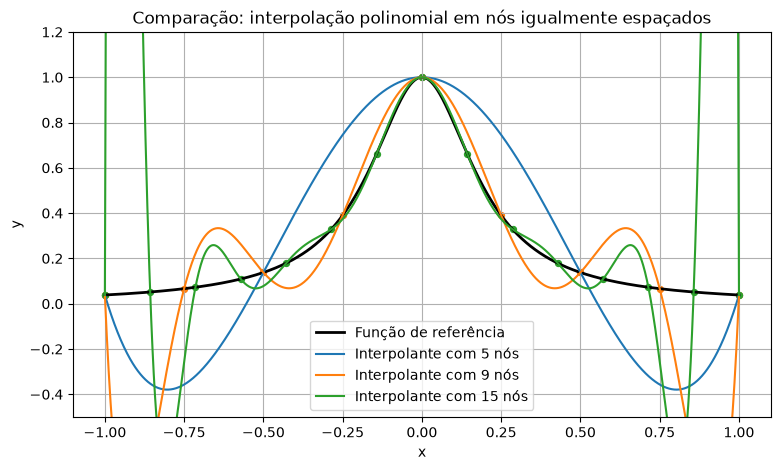

In [11]:
def f(t):
    return 1/(1+25*t**2)

t_plot = np.linspace(-1,1,1000)
plt.figure(figsize=(9,5))
plt.plot(t_plot,f(t_plot),color="black",linewidth=2,label="Função de referência")
for n in [5, 9, 15]:
    tn=np.linspace(-1,1,n)
    pn=np.polynomial.Polynomial.fit(tn,f(tn),deg=n-1).convert()
    plt.plot(t_plot,pn(t_plot),label=f"Interpolante com {n} nós")
    plt.scatter(tn,f(tn),s=18)
plt.ylim(-0.5,1.2); plt.grid(True); plt.legend(); plt.title("Comparação: interpolação polinomial em nós igualmente espaçados")
plt.xlabel("x"); plt.ylabel("y"); plt.show()

**Observação guiada:**

- Todas as curvas interpoladoras passam pelos pontos utilizados?
- O que ocorre perto das extremidades quando aumenta o número de nós?
- Para muitos dados, que alternativas vocês investigariam (por exemplo, interpolação por partes/splines)?

O objetivo é observar, não memorizar uma regra universal: o comportamento depende dos dados, dos nós e do método.

**Resposta do grupo:**
- **Passam pelos pontos?** Sim. Nos nós, a diferença entre cada interpolante e $f$ fica entre $10^{-15}$ e $10^{-12}$ (conferido no complemento abaixo). Ela cresce um pouco com o grau, por arredondamento, mas continua desprezível.
- **Extremidades:** quanto mais nós, **pior** perto das pontas. No centro o ajuste melhora, mas perto de $x=\pm1$ a curva oscila cada vez mais: o maior erro é $\approx0{,}44$ com 5 nós, $\approx1{,}05$ com 9 e $\approx7{,}2$ com 15. Com 15 nós a curva chega a sair do gráfico: o `ylim(-0.5, 1.2)` corta o pico, que passa de $7$ perto de $x=\pm0{,}96$. Mais pontos igualmente espaçados não deram uma curva melhor, e esse é o fenômeno de Runge.
- **Alternativas:**
  1. **splines cúbicas**: um polinômio de grau 3 em cada trecho entre nós, colados com primeira e segunda derivadas contínuas, e o grau não cresce com o número de pontos;
  2. **nós de Chebyshev**, mais concentrados perto das extremidades, quando podemos escolher onde medir;
  3. interpolação **linear por partes**, simples e sem oscilação;
  4. **regressão** com grau baixo, se os dados tiverem ruído.

  Testamos as duas primeiras no complemento abaixo.

### Complemento do grupo: a escolha dos nós e as splines

Um dos objetivos da atividade é investigar como a escolha dos nós afeta o resultado. Comparamos, com os mesmos **15 nós**:
- nós **igualmente espaçados** (como acima);
- nós de **Chebyshev**, $t_k=\cos\!\left(\frac{(2k+1)\pi}{2n}\right)$, $k=0,\dots,n-1$, mais juntos nas pontas;
- uma **spline cúbica** (`scipy.interpolate.CubicSpline`) nos nós igualmente espaçados.

Depois repetimos a conta para 5, 9, 15 e 21 nós.

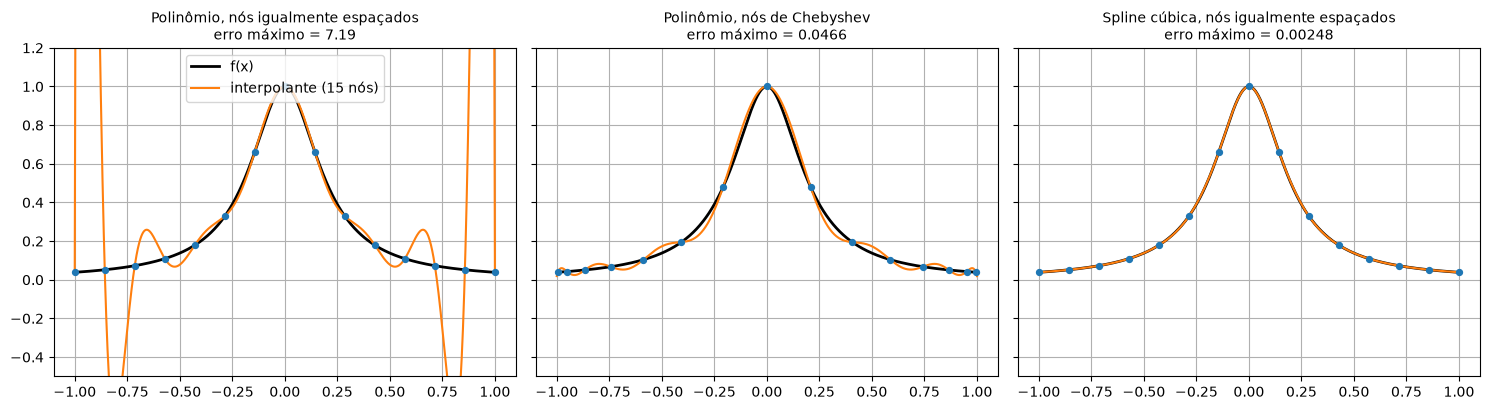

 nós | erro máx. (igual. esp.) | erro máx. (Chebyshev) | erro máx. (spline) | maior erro nos nós (igual. esp.)
   5 |                  0.4383 |                0.4020 |             0.3171 | 2.6e-15
   9 |                  1.0452 |                0.1708 |             0.0562 | 2.4e-14
  15 |                  7.1923 |                0.0466 |             0.0025 | 2.8e-12
  21 |                 59.7684 |                0.0153 |             0.0032 | 3.0e-10


In [12]:
from scipy.interpolate import CubicSpline

def nos_chebyshev(n):
    k = np.arange(n)                       # 0, 1, ..., n-1
    return np.cos((2*k + 1) * np.pi / (2*n))

n = 15
t_igual = np.linspace(-1, 1, n)
t_cheb = nos_chebyshev(n)
p_igual = np.polynomial.Polynomial.fit(t_igual, f(t_igual), deg=n-1).convert()
p_cheb = np.polynomial.Polynomial.fit(t_cheb, f(t_cheb), deg=n-1).convert()
spline = CubicSpline(t_igual, f(t_igual))

fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
casos = [(p_igual, t_igual, "Polinômio, nós igualmente espaçados"),
         (p_cheb,  t_cheb,  "Polinômio, nós de Chebyshev"),
         (spline,  t_igual, "Spline cúbica, nós igualmente espaçados")]
for ax, (curva, nos, titulo) in zip(eixos, casos):
    ax.plot(t_plot, f(t_plot), color="black", lw=2, label="f(x)")
    ax.plot(t_plot, curva(t_plot), color="tab:orange", label="interpolante (15 nós)")
    ax.scatter(nos, f(nos), s=18, zorder=3)
    erro = np.max(np.abs(curva(t_plot) - f(t_plot)))
    ax.set_title(f"{titulo}\nerro máximo = {erro:.3g}", fontsize=10)
    ax.set_ylim(-0.5, 1.2); ax.grid(True)
eixos[0].legend(loc="upper center"); plt.tight_layout(); plt.show()

print(" nós | erro máx. (igual. esp.) | erro máx. (Chebyshev) | erro máx. (spline) | maior erro nos nós (igual. esp.)")
for n in [5, 9, 15, 21]:
    ti, tc = np.linspace(-1, 1, n), nos_chebyshev(n)
    pi_ = np.polynomial.Polynomial.fit(ti, f(ti), deg=n-1).convert()
    pc_ = np.polynomial.Polynomial.fit(tc, f(tc), deg=n-1).convert()
    sp_ = CubicSpline(ti, f(ti))
    erro = lambda g: np.max(np.abs(g(t_plot) - f(t_plot)))
    print(f"{n:4d} | {erro(pi_):23.4f} | {erro(pc_):21.4f} | {erro(sp_):18.4f} | {np.max(np.abs(pi_(ti) - f(ti))):.1e}")

**O que observamos:** com nós igualmente espaçados, o erro **cresce** com o número de nós (de $\approx0{,}44$ com 5 nós para $\approx60$ com 21). Com a mesma quantidade de nós nas posições de Chebyshev, o erro **diminui** (de $\approx0{,}40$ para $\approx0{,}015$). A spline cúbica, mesmo com nós igualmente espaçados, fica na casa de $10^{-3}$ a partir de 15 nós e não oscila.

Ou seja, o problema não é usar muitos pontos: é **onde** eles estão e **qual** função usamos para ligá-los. Quando não dá para escolher onde medir (dados de sensor costumam vir igualmente espaçados no tempo), a spline é a saída mais simples.

## 10. Interpolação versus regressão

Na interpolação, a curva passa pelos pontos fornecidos. Na **regressão**, escolhemos um modelo que procura representar a tendência geral, sem exigir que passe por cada observação. A regressão pode ser mais apropriada quando há ruído de medição.

| Aspecto | Interpolação | Regressão |
|---|---|---|
| Passa por todos os dados? | Sim (no caso polinomial exato) | Em geral, não |
| Uso comum | Estimar entre dados conhecidos | Representar tendência com dados ruidosos |
| Risco | Oscilação ou extrapolação ruim | Modelo inadequado ou resíduos grandes |

**Expliquem com suas palavras por que a curva interpoladora do conjunto B não prova que as medições são exatas ou sem ruído.**

**Resposta do grupo:** Com quatro valores de $x$ distintos, **sempre** existe um polinômio de grau até 3 que passa exatamente pelos quatro pontos, quaisquer que sejam os valores de $y$, até números sorteados. Então "a curva passa por todas as medições" é garantido pela matemática e não diz nada sobre a qualidade dos dados.

A seção 8 mostra isso na prática: trocamos $2{,}7$ por $3{,}2$ e a nova curva também passou perfeitamente por todos os pontos. A interpolação usa todos os graus de liberdade para reproduzir os dados, então o resíduo é zero **por construção**. Se houver ruído, ele é copiado para a curva, e não detectado. Para avaliar o ruído precisaríamos de mais medições do que parâmetros do modelo (regressão), de medições repetidas ou da precisão do instrumento.

Na célula abaixo, uma reta de regressão para o conjunto B deixa resíduos de até $\approx0{,}27$. Eles podem ser ruído ou uma curvatura real dos dados, e a interpolação simplesmente esconde essa pergunta.

Reta de mínimos quadrados: 1.09 + 0.94 x
Resíduos da reta (dado − modelo):         [ 0.11 -0.03 -0.27  0.19]
Resíduos da interpolação (dado − modelo): [0. 0. 0. 0.]


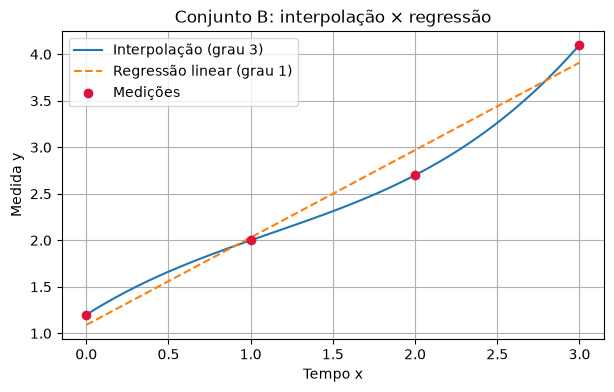

In [13]:
# com grau 1 e 4 pontos não dá para passar por todos: o fit vira regressão de verdade
reta = np.polynomial.Polynomial.fit(xB, yB, deg=1).convert()
print("Reta de mínimos quadrados:", reta)
print("Resíduos da reta (dado − modelo):        ", limpa(yB - reta(xB), 3))
print("Resíduos da interpolação (dado − modelo):", limpa(yB - pB(xB), 3))

plt.figure(figsize=(7, 4))
plt.plot(xb_plot, pB(xb_plot), label="Interpolação (grau 3)")
plt.plot(xb_plot, reta(xb_plot), "--", label="Regressão linear (grau 1)")
plt.scatter(xB, yB, color="crimson", zorder=3, label="Medições")
plt.grid(True); plt.legend(); plt.xlabel("Tempo x"); plt.ylabel("Medida y")
plt.title("Conjunto B: interpolação × regressão"); plt.show()

## 11. Síntese e entrega

Escrevam uma síntese de 6–10 linhas, incluindo:
1. o que significa interpolar e a diferença para extrapolar;
2. quais ferramentas foram testadas e se concordaram;
3. o que mudou quando um dado foi alterado;
4. uma limitação observada na interpolação polinomial;
5. em que situação prática usariam o método e que cautela teriam.

**Síntese do grupo:**

Interpolar é construir uma função (aqui, um polinômio) que passa exatamente pelos pontos dados e usá-la para estimar valores **dentro** do intervalo dos nós. Extrapolar é usar a mesma função fora desse intervalo, onde nenhum dado controla a curva: no conjunto A, $P(2)=1$ "mostra" a curva voltando a subir sem que nada nos dados indique isso. Testamos o NumPy, o WolframAlpha e o GeoGebra, e os três deram $P(x)=x^2-2x+1=(x-1)^2$, com $P(-1{,}5)=6{,}25$ e $P(0{,}5)=0{,}25$. Eles só diferiram na forma de apresentar (o WolframAlpha devolveu a forma de Newton, $(x-4)(x+2)+9$) e no arredondamento (o NumPy mostra um termo de $x^3$ da ordem de $10^{-15}$). Quando aumentamos em $0{,}5$ a medição de $x=2$ no conjunto B, a estimativa em $x=1{,}5$ passou de $2{,}3125$ para $2{,}5938$ e a curva mudou em todo o intervalo, não só perto do ponto: cada dado influencia o polinômio inteiro. Uma limitação que vimos é o fenômeno de Runge: com nós igualmente espaçados, aumentar o grau fez o erro nas pontas crescer (de $\approx0{,}44$ com 5 nós para $\approx7{,}2$ com 15) em vez de diminuir. Usaríamos interpolação, por exemplo, para estimar a temperatura entre duas leituras horárias ou um valor entre duas linhas de uma tabela, com poucos pontos próximos e grau baixo (ou spline), sem extrapolar e lembrando que, se os dados tiverem ruído, a regressão é mais adequada.


### Checklist
- [x] Expliquei o papel dos nós e do polinômio interpolador.
- [x] Conferi numericamente que o polinômio reproduz os dados.
- [x] Calculei e classifiquei valores consultados como interpolação/extrapolação.
- [x] Comparei duas ferramentas com os mesmos dados.
- [x] Fiz o experimento de alteração de dado e registrei observações.
- [x] Analisei o exemplo com muitos nós e discuti limitações.



### Resumo: o Python usado nesta atividade

| Onde | Conceito |
|---|---|
| Seções 3 e 4 | `np.array(..., dtype=float)`; `Polynomial.fit(...).convert()`; `.coef`; avaliar um polinômio num vetor inteiro |
| Complemento da seção 4 | laços `for` com `range` decrescente; cópia de vetor; esquema de Horner |
| Complemento da seção 5 | `np.append` (gera um vetor novo); duas curvas no mesmo gráfico |
| Seção 6 | comparação encadeada `a <= q <= b`; f-strings com formato (`:.6f`, `:.2e`) |
| Complemento da seção 8 | parâmetro com valor padrão (`casas=5`); `-0.0` × `0.0` |
| Complemento da seção 9 | `np.cos` em vetor; `scipy.interpolate.CubicSpline`; `plt.subplots` com eixos lado a lado |
| Complemento da seção 10 | `Polynomial.fit` com grau baixo = regressão por mínimos quadrados |